# Modeling
## Home Credit Default Risk

### 1. Purpose of This Notebook: Feature Selection

This notebook investigates **feature relevance and selection for the Home Credit Default Risk project**, building on the Logistic Regression and Hist Gradient Boosting baselines and the exploratory feature analysis conducted in previous notebooks.

The goal is to assess the predictive contribution of the ten engineered features and determine whether a smaller feature set can preserve model performance while improving simplicity and interpretability.

The analysis focuses on:

- **Correlation Analysis:** Examining linear relationships between features and the target, as well as potential redundancy among predictors;
- **Permutation Feature Importance:** Measuring the contribution of individual features to the Logistic Regression and Hist Gradient Boosting baselines using Average Precision;
- **Feature Subset Evaluation:** Comparing models trained with 10, 7, and 5 features through stratified cross-validation, using Average Precision and ROC-AUC as evaluation metrics;
- **Performance vs. Complexity:** Assessing whether feature reduction leads to meaningful changes in predictive performance.

The findings will guide the selection of candidate feature sets for subsequent hyperparameter tuning and model optimization experiments.

# 1. Imports & Configuration

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.inspection import permutation_importance
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    RocCurveDisplay, 
    roc_auc_score
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier

In [2]:
import mlflow
import mlflow.sklearn

mlflow.set_tracking_uri("sqlite:///../mlflow.db")
mlflow.set_experiment("home-credit-default-risk")

<Experiment: artifact_location='/home/priscila/Desktop/Estudos/home_credit_default_risk_mle/notebooks/mlruns/1', creation_time=1790515154866, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1790515154866, lifecycle_stage='active', name='home-credit-default-risk', tags={}, trace_location=None, workspace='default'>

# 2. Getting Data

In [3]:
selected_features = [
    # 1. Payment Behavior
    "INST_LATE_RATIO",
    "INST_DPD_30_RATIO",
    "POS_DPD_RATIO",
    "CC_PAYMENT_TO_BALANCE_RATIO",

    # 2. Credit Exposure
    "BUREAU_ACTIVE_LOAN_COUNT",
    "BUREAU_OVERDUE_LOAN_RATIO",
    "BUREAU_ACTIVE_DEBT_RATIO",
    "CC_UTIL_MEAN",

    # 3. Previous Applications
    "PREV_REFUSED_RATIO",
    "PREV_CREDIT_TO_APPLICATION_RATIO_MEAN",
]

splits = pd.read_parquet(
    "../data/split_assignment.parquet"
)

df = pd.read_parquet(
    "../data/feature_store_train.parquet",
    columns=["SK_ID_CURR", "TARGET"] + selected_features,
)

df_train = df.merge(
    splits,
    on="SK_ID_CURR",
    validate="one_to_one",
).query("SPLIT == 'development'")

print(f"Rows (development): {df_train.shape[0]:,}")
print(f"Total columns: {df_train.shape[1]:,}")

Rows (development): 246,008
Total columns: 13


In [4]:
df.head()

,SK_ID_CURR,TARGET,INST_LATE_RATIO,INST_DPD_30_RATIO,POS_DPD_RATIO,CC_PAYMENT_TO_BALANCE_RATIO,BUREAU_ACTIVE_LOAN_COUNT,BUREAU_OVERDUE_LOAN_RATIO,BUREAU_ACTIVE_DEBT_RATIO,CC_UTIL_MEAN,PREV_REFUSED_RATIO,PREV_CREDIT_TO_APPLICATION_RATIO_MEAN
0,100002,1,0.000000,0.0,0.0,NaN,2.0,0.375,0.509931,NaN,0.000000,1.000000
1,100003,0,0.000000,0.0,0.0,NaN,1.0,0.000,0.000000,NaN,0.000000,1.057664
2,100004,0,0.000000,0.0,0.0,NaN,0.0,0.000,0.000000,NaN,0.000000,0.828021
3,100006,0,0.000000,0.0,0.0,0.0,NaN,NaN,NaN,0.0,0.111111,0.675123
4,100007,0,0.242424,0.0,0.0,NaN,0.0,0.000,0.000000,NaN,0.000000,1.046356


In [5]:
X_development = df_train.drop(columns=["SK_ID_CURR", "TARGET", "SPLIT"])
y_development = df_train["TARGET"]

X_train, X_val, y_train, y_val = train_test_split(
    X_development,
    y_development,
    test_size=0.25,
    stratify=y_development,
    random_state=42,
)

In [6]:
print(f"Train size: {len(X_train):,}")
print(f"Validation size: {len(X_val):,}")

print(f"Train default rate: {y_train.mean():.2%}")
print(f"Validation default rate: {y_val.mean():.2%}")

Train size: 184,506
Validation size: 61,502
Train default rate: 8.07%
Validation default rate: 8.07%


# 3. Correlation Analysis

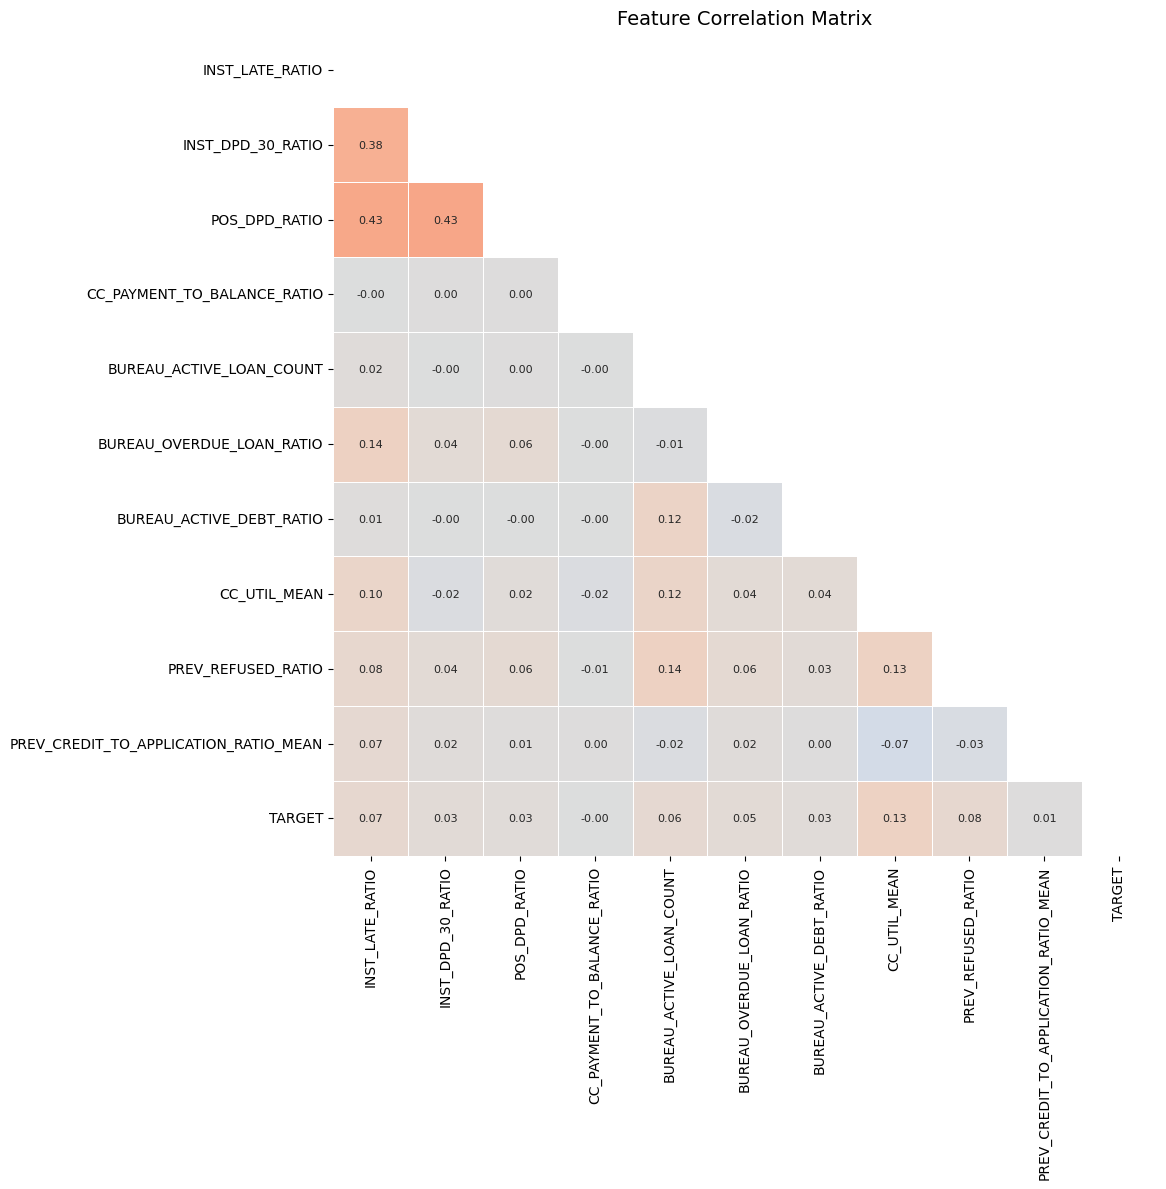

In [21]:
df = X_train.copy()
df["TARGET"] = y_train

corr_matrix = df.corr(method="pearson", numeric_only=True)

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

fig, ax = plt.subplots(figsize=(14, 12))

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    annot_kws={"size": 8},
    cbar=False,
    ax=ax,
)

ax.set_title("Feature Correlation Matrix", fontsize=14)
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()

# Compute maximum absolute feature correlation
feature_corr = corr_matrix.drop(
    index="TARGET",
    columns="TARGET",
)

upper_triangle = feature_corr.where(
    np.triu(np.ones(feature_corr.shape, dtype=bool), k=1)
)

max_corr = upper_triangle.abs().max().max()

with mlflow.start_run(run_name="feature-correlation-analysis"):

    mlflow.log_params({
        "analysis": "feature_correlation",
        "correlation_method": "pearson",
        "n_features": X_train.shape[1],
        "dataset": "training",
    })

    mlflow.log_metric(
        "max_absolute_feature_correlation",
        float(max_corr),
    )

    mlflow.log_figure(
        fig,
        "correlation/feature_correlation_heatmap.png",
    )

    mlflow.log_table(
        corr_matrix.reset_index().rename(columns={"index": "feature"}),
        "correlation/feature_correlation_matrix.json",
    )

plt.show()

### Correlation Analysis:

The correlation analysis reveals generally weak linear associations between individual features and the target variable, with `CC_UTIL_MEAN` exhibiting the strongest positive correlation (0.13).

Pairwise correlations among predictors are also relatively low, suggesting limited linear redundancy within the current feature set. Moderate correlations were observed among payment default indicators, which capture related aspects of credit behavior.

# 4. Permutation Importance - Logistic Regression

In [70]:
db_path = Path("../mlflow.db").resolve()

mlflow.set_tracking_uri(f"sqlite:///{db_path}")

run_id = "0a33286069b44bd494b65b348d30d13d"

run = mlflow.get_run(run_id)

print("Run ID:", run.info.run_id)
print("Experiment ID:", run.info.experiment_id)
print("Artifact URI:", run.info.artifact_uri)

models = mlflow.search_logged_models(
    filter_string=f"source_run_id = '{run_id}'"
)

print("Model ID:", models.model_id[0])
print("Model Name:", models.name[0])

model_id = models.model_id[0]

baseline_pipeline = mlflow.sklearn.load_model(
    f"models:/{model_id}"
)

print(baseline_pipeline)

Run ID: 0a33286069b44bd494b65b348d30d13d
Experiment ID: 1
Artifact URI: /home/priscila/Desktop/Estudos/home_credit_default_risk_mle/notebooks/mlruns/1/0a33286069b44bd494b65b348d30d13d/artifacts
Model ID: m-517a9500caa745b48632f1cc051ba548
Model Name: model
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('model', LogisticRegression(max_iter=1000, random_state=42))])


In [54]:
y_val_proba = baseline_pipeline.predict_proba(X_val)[:, 1]

baseline_pr_auc = average_precision_score(
    y_val,
    y_val_proba,
)

result = permutation_importance(
    estimator=baseline_pipeline,
    X=X_val,
    y=y_val,
    scoring="average_precision",
    n_repeats=10,
    random_state=42,
    n_jobs=-1,
)

importance_df = pd.DataFrame({
    "feature": X_val.columns,
    "importance_mean": result.importances_mean,
    "importance_std": result.importances_std,
}).sort_values(
    by="importance_mean",
    ascending=False,
)

importance_df

,feature,importance_mean,importance_std
7,CC_UTIL_MEAN,0.016142,0.000721
8,PREV_REFUSED_RATIO,0.014804,0.001015
0,INST_LATE_RATIO,0.010110,0.000903
6,BUREAU_ACTIVE_DEBT_RATIO,0.009471,0.000775
4,BUREAU_ACTIVE_LOAN_COUNT,0.004804,0.000379
5,BUREAU_OVERDUE_LOAN_RATIO,0.000967,0.000559
2,POS_DPD_RATIO,0.000088,0.000022
3,CC_PAYMENT_TO_BALANCE_RATIO,-0.000002,0.000001
9,PREV_CREDIT_TO_APPLICATION_RATIO_MEAN,-0.000069,0.000099
1,INST_DPD_30_RATIO,-0.000257,0.000126


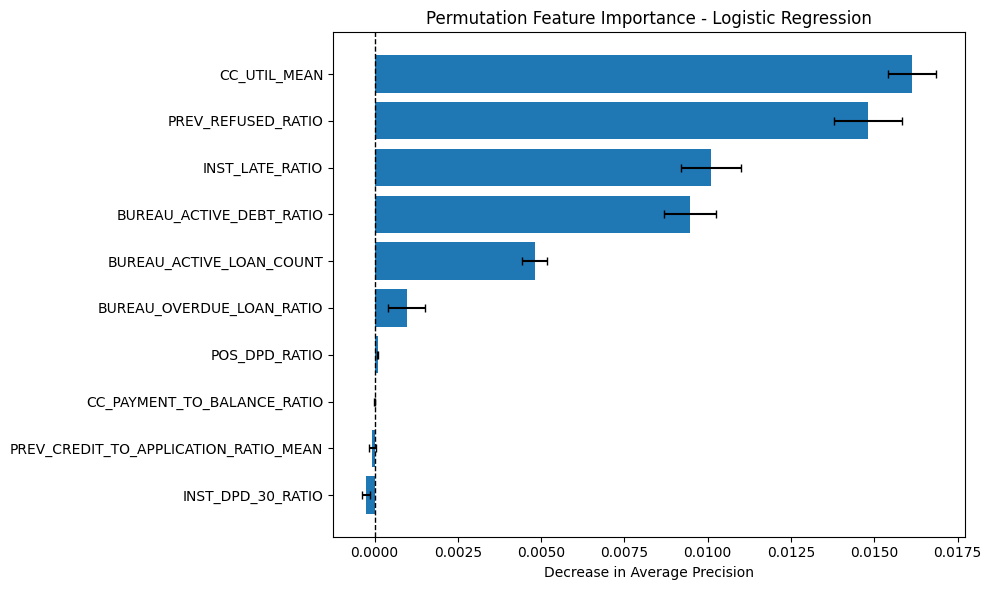

In [55]:
fig, ax = plt.subplots(figsize=(10, 6))

importance_plot = importance_df.sort_values(
    by="importance_mean",
    ascending=True,
)

ax.barh(
    importance_plot["feature"],
    importance_plot["importance_mean"],
    xerr=importance_plot["importance_std"],
    capsize=3,
)

ax.axvline(
    x=0,
    color="black",
    linestyle="--",
    linewidth=1,
)

ax.set_title("Permutation Feature Importance - Logistic Regression")
ax.set_xlabel("Decrease in Average Precision")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

In [56]:
y_val_proba = baseline_pipeline.predict_proba(X_val)[:, 1]

baseline_ap = average_precision_score(
    y_val,
    y_val_proba,
)

reference_ap = y_val.mean()

importance_df["relative_importance_pct"] = (
    importance_df["importance_mean"] / baseline_ap * 100
)

importance_df["gain_importance_pct"] = (
    importance_df["importance_mean"]
    / (baseline_ap - reference_ap)
    * 100
)

print(f"Baseline AP: {baseline_ap:.4f}")
print(f"Reference AP: {reference_ap:.4f}")

importance_df

Baseline AP: 0.1361
Reference AP: 0.0807


,feature,importance_mean,importance_std,relative_importance_pct,gain_importance_pct
7,CC_UTIL_MEAN,0.016142,0.000721,11.857224,29.134558
8,PREV_REFUSED_RATIO,0.014804,0.001015,10.874643,26.720244
0,INST_LATE_RATIO,0.010110,0.000903,7.426265,18.247183
6,BUREAU_ACTIVE_DEBT_RATIO,0.009471,0.000775,6.957169,17.094561
4,BUREAU_ACTIVE_LOAN_COUNT,0.004804,0.000379,3.528925,8.670972
5,BUREAU_OVERDUE_LOAN_RATIO,0.000967,0.000559,0.710547,1.745896
2,POS_DPD_RATIO,0.000088,0.000022,0.064476,0.158425
3,CC_PAYMENT_TO_BALANCE_RATIO,-0.000002,0.000001,-0.001531,-0.003761
9,PREV_CREDIT_TO_APPLICATION_RATIO_MEAN,-0.000069,0.000099,-0.050804,-0.124832
1,INST_DPD_30_RATIO,-0.000257,0.000126,-0.188789,-0.463876


### Permutation Importance: Logistic Regression

The Logistic Regression baseline achieved an Average Precision of 0.1361, compared with a reference value of 0.0807, representing a relative improvement of approximately 68.6%.

Permutation Importance revealed that `CC_UTIL_MEAN` and `PREV_REFUSED_RATIO` were the most influential predictors, with performance reductions of approximately 0.0161 and 0.0148, respectively.

These reductions correspond to approximately 29.1% and 26.7% of the model's improvement over the reference AP, highlighting their relevance to the current model.

In contrast, five features exhibited negligible or negative importance, suggesting opportunities for feature set simplification.

# 5. Feature Subset Evaluation - Logistic Regression

In [57]:
feature_sets = {
    "baseline": X_train.columns.tolist(),

    "reduced_7": importance_df.head(7)["feature"].tolist(),

    "reduced_5": importance_df.head(5)["feature"].tolist(),
}

for name, features in feature_sets.items():
    print(f"{name}: {len(features)} features")
    print(features)
    print()

baseline: 10 features
['INST_LATE_RATIO', 'INST_DPD_30_RATIO', 'POS_DPD_RATIO', 'CC_PAYMENT_TO_BALANCE_RATIO', 'BUREAU_ACTIVE_LOAN_COUNT', 'BUREAU_OVERDUE_LOAN_RATIO', 'BUREAU_ACTIVE_DEBT_RATIO', 'CC_UTIL_MEAN', 'PREV_REFUSED_RATIO', 'PREV_CREDIT_TO_APPLICATION_RATIO_MEAN']

reduced_7: 7 features
['CC_UTIL_MEAN', 'PREV_REFUSED_RATIO', 'INST_LATE_RATIO', 'BUREAU_ACTIVE_DEBT_RATIO', 'BUREAU_ACTIVE_LOAN_COUNT', 'BUREAU_OVERDUE_LOAN_RATIO', 'POS_DPD_RATIO']

reduced_5: 5 features
['CC_UTIL_MEAN', 'PREV_REFUSED_RATIO', 'INST_LATE_RATIO', 'BUREAU_ACTIVE_DEBT_RATIO', 'BUREAU_ACTIVE_LOAN_COUNT']



In [62]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

scoring = {
    "average_precision": "average_precision",
    "roc_auc": "roc_auc",
}

results = []
fold_results = []

for name, features in feature_sets.items():

    pipeline = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            (
                "model",
                LogisticRegression(
                    max_iter=1000,
                    random_state=42,
                ),
            ),
        ]
    )

    cv_results = cross_validate(
        estimator=pipeline,
        X=X_train[features],
        y=y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
    )

    for fold, ap in enumerate(
            cv_results["test_average_precision"], start=1
        ):
            fold_results.append({
                "experiment": name,
                "fold": fold,
                "average_precision": ap,
            })

    results.append({
        "experiment": name,
        "n_features": len(features),
        "ap_mean": cv_results["test_average_precision"].mean(),
        "ap_std": cv_results["test_average_precision"].std(),
        "roc_auc_mean": cv_results["test_roc_auc"].mean(),
        "roc_auc_std": cv_results["test_roc_auc"].std(),
    })

results_df = pd.DataFrame(results)
results_df

,experiment,n_features,ap_mean,ap_std,roc_auc_mean,roc_auc_std
0,baseline,10,0.134920,0.002408,0.637416,0.004009
1,reduced_7,7,0.134649,0.002597,0.636830,0.004538
2,reduced_5,5,0.133799,0.002345,0.633776,0.003784


In [66]:
fold_df = pd.DataFrame(fold_results)

display(
    fold_df.pivot(
        index="fold",
        columns="experiment",
        values="average_precision",
    )
)

experiment,baseline,reduced_5,reduced_7
fold,,,
1,0.130853,0.129792,0.130312
2,0.137874,0.136661,0.137804
3,0.136350,0.134872,0.136432
4,0.133859,0.132812,0.133451
5,0.135663,0.134857,0.135245


In [63]:
baseline_ap = results_df.loc[
    results_df["experiment"] == "baseline",
    "ap_mean",
].iloc[0]

results_df["delta_ap"] = (
    results_df["ap_mean"] - baseline_ap
)

display(
    results_df.sort_values(
        by="ap_mean",
        ascending=False,
    )
)

,experiment,n_features,ap_mean,ap_std,roc_auc_mean,roc_auc_std,delta_ap
0,baseline,10,0.134920,0.002408,0.637416,0.004009,0.000000
1,reduced_7,7,0.134649,0.002597,0.636830,0.004538,-0.000271
2,reduced_5,5,0.133799,0.002345,0.633776,0.003784,-0.001121


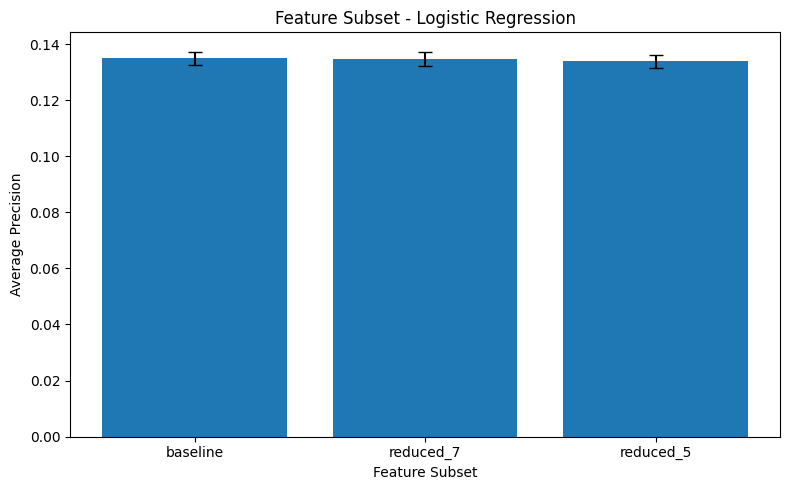

In [67]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    results_df["experiment"],
    results_df["ap_mean"],
    yerr=results_df["ap_std"],
    capsize=5,
)

ax.set_title("Feature Subset - Logistic Regression")
ax.set_xlabel("Feature Subset")
ax.set_ylabel("Average Precision")

plt.tight_layout()
plt.show()

In [68]:
with mlflow.start_run(
    run_name="logistic-regression-feature-subset-evaluation"
):

    # Experiment configuration
    mlflow.log_params({
        "analysis": "feature_subset_evaluation",
        "model": "LogisticRegression",
        "selection_method": "permutation_importance",
        "cv_strategy": "StratifiedKFold",
        "n_splits": 5,
        "random_state": 42,
        "primary_metric": "average_precision",
        "imputer": "median",
        "scaler": "StandardScaler",
    })

    # Evaluation metrics
    for _, row in results_df.iterrows():

        name = row["experiment"]

        for metric in [
            "ap_mean",
            "ap_std",
            "roc_auc_mean",
            "roc_auc_std",
            "delta_ap",
        ]:
            mlflow.log_metric(
                f"{name}_{metric}",
                float(row[metric]),
            )

    # Feature subsets
    mlflow.log_dict(
        feature_sets,
        "feature_selection/feature_subsets.json",
    )

    # Results table
    mlflow.log_table(
        results_df,
        "feature_selection/subset_comparison.json",
    )

    # Comparison plot
    mlflow.log_figure(
        fig,
        "feature_selection/subset_comparison.png",
    )

    # Results per fold
    mlflow.log_table(
    fold_df,
    "feature_selection/fold_results.json",
    )

    mlflow.log_text(
        """
    # Feature Subset Evaluation: Conclusions

    Reducing the feature set from 10 to 5 predictors
    resulted in a marginal decrease in Average Precision
    (0.1349 to 0.1338).

    The results suggest that a more compact feature set
    can preserve most of the baseline predictive performance.

    Both feature sets will be considered in subsequent
    modeling experiments.
    """,
        "feature_selection/conclusions.md",
    )

### Feature Subset Evaluation: Logistic Regression

The FSE study evaluated Logistic Regression models trained with 10, 7, and 5 features using five-fold stratified cross-validation.

Reducing the feature set from 10 to 5 predictors resulted in only a marginal decrease in Average Precision, from 0.1349 to 0.1338, representing a relative reduction of approximately 0.83%.

ROC-AUC also remained relatively stable, decreasing from 0.6374 to 0.6338.

These findings suggest that the predictive contribution of the excluded features is limited under the current modeling configuration, supporting the possibility of a few features model.

Given the small performance differences, both the complete and reduced feature sets will be retained as candidates for subsequent hyperparameter optimization experiments.

# 6. Permutation Importance - Hist Gradient Boosting

In [71]:
db_path = Path("../mlflow.db").resolve()

mlflow.set_tracking_uri(f"sqlite:///{db_path}")

run_id = "68794562639d45b4b1fe8d07c6a56bc9"

run = mlflow.get_run(run_id)

print("Run ID:", run.info.run_id)
print("Experiment ID:", run.info.experiment_id)
print("Artifact URI:", run.info.artifact_uri)

models = mlflow.search_logged_models(
    filter_string=f"source_run_id = '{run_id}'"
)

print("Model ID:", models.model_id[0])
print("Model Name:", models.name[0])

model_id = models.model_id[0]

hgb_pipeline = mlflow.sklearn.load_model(
    f"models:/{model_id}"
)

print(hgb_pipeline)

Run ID: 68794562639d45b4b1fe8d07c6a56bc9
Experiment ID: 1
Artifact URI: /home/priscila/Desktop/Estudos/home_credit_default_risk_mle/notebooks/mlruns/1/68794562639d45b4b1fe8d07c6a56bc9/artifacts
Model ID: m-54217641828e4d0aa8fb8549fe5a0439
Model Name: model
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('model', HistGradientBoostingClassifier(random_state=42))])


In [72]:
y_val_proba = hgb_pipeline.predict_proba(X_val)[:, 1]

baseline_pr_auc = average_precision_score(
    y_val,
    y_val_proba,
)

result = permutation_importance(
    estimator=hgb_pipeline,
    X=X_val,
    y=y_val,
    scoring="average_precision",
    n_repeats=10,
    random_state=42,
    n_jobs=-1,
)

importance_df = pd.DataFrame({
    "feature": X_val.columns,
    "importance_mean": result.importances_mean,
    "importance_std": result.importances_std,
}).sort_values(
    by="importance_mean",
    ascending=False,
)

importance_df

,feature,importance_mean,importance_std
7,CC_UTIL_MEAN,0.022084,0.000508
6,BUREAU_ACTIVE_DEBT_RATIO,0.019328,0.001075
8,PREV_REFUSED_RATIO,0.016033,0.001253
4,BUREAU_ACTIVE_LOAN_COUNT,0.009366,0.001074
3,CC_PAYMENT_TO_BALANCE_RATIO,0.008636,0.000954
0,INST_LATE_RATIO,0.008218,0.000888
9,PREV_CREDIT_TO_APPLICATION_RATIO_MEAN,0.005029,0.001159
5,BUREAU_OVERDUE_LOAN_RATIO,0.003891,0.000755
2,POS_DPD_RATIO,-0.000041,0.000216
1,INST_DPD_30_RATIO,-0.000260,0.000240


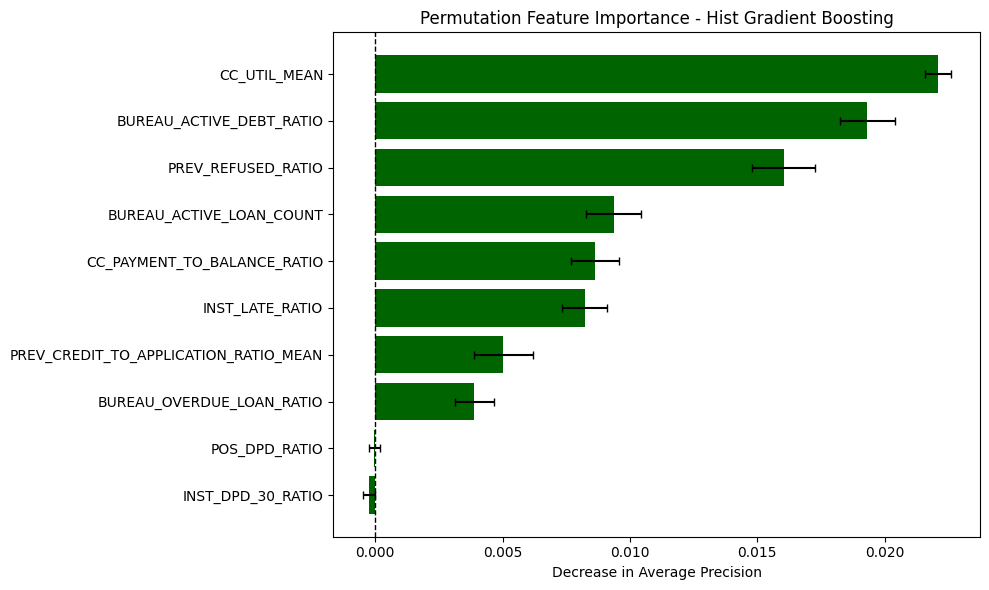

In [80]:
fig, ax = plt.subplots(figsize=(10, 6))

importance_plot = importance_df.sort_values(
    by="importance_mean",
    ascending=True,
)

ax.barh(
    importance_plot["feature"],
    importance_plot["importance_mean"],
    xerr=importance_plot["importance_std"],
    capsize=3,
    color="darkgreen"
)

ax.axvline(
    x=0,
    color="black",
    linestyle="--",
    linewidth=1,
)

ax.set_title("Permutation Feature Importance - Hist Gradient Boosting")
ax.set_xlabel("Decrease in Average Precision")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

In [74]:
y_val_proba = hgb_pipeline.predict_proba(X_val)[:, 1]

baseline_ap = average_precision_score(
    y_val,
    y_val_proba,
)

reference_ap = y_val.mean()

importance_df["relative_importance_pct"] = (
    importance_df["importance_mean"] / baseline_ap * 100
)

importance_df["gain_importance_pct"] = (
    importance_df["importance_mean"]
    / (baseline_ap - reference_ap)
    * 100
)

print(f"Baseline AP: {baseline_ap:.4f}")
print(f"Reference AP: {reference_ap:.4f}")

importance_df

Baseline AP: 0.1458
Reference AP: 0.0807


,feature,importance_mean,importance_std,relative_importance_pct,gain_importance_pct
7,CC_UTIL_MEAN,0.022084,0.000508,15.145887,33.933617
6,BUREAU_ACTIVE_DEBT_RATIO,0.019328,0.001075,13.255858,29.699101
8,PREV_REFUSED_RATIO,0.016033,0.001253,10.995952,24.635891
4,BUREAU_ACTIVE_LOAN_COUNT,0.009366,0.001074,6.423689,14.391961
3,CC_PAYMENT_TO_BALANCE_RATIO,0.008636,0.000954,5.922601,13.269298
0,INST_LATE_RATIO,0.008218,0.000888,5.636013,12.627211
9,PREV_CREDIT_TO_APPLICATION_RATIO_MEAN,0.005029,0.001159,3.448760,7.726778
5,BUREAU_OVERDUE_LOAN_RATIO,0.003891,0.000755,2.668653,5.978987
2,POS_DPD_RATIO,-0.000041,0.000216,-0.028201,-0.063183
1,INST_DPD_30_RATIO,-0.000260,0.000240,-0.178445,-0.399796


### Permutation Importance: HistGradientBoosting 

Permutation Feature Importance was applied to the HistGradientBoosting baseline using Average Precision as the evaluation metric.

The model achieved an Average Precision of 0.1458, compared with a reference value of 0.0807.

`CC_UTIL_MEAN`, `BUREAU_ACTIVE_DEBT_RATIO`, and `PREV_REFUSED_RATIO` emerged as the most influential predictors.

Compared with Logistic Regression, HistGradientBoosting showed greater dependence on `CC_PAYMENT_TO_BALANCE_RATIO` and `PREV_CREDIT_TO_APPLICATION_RATIO_MEAN`, suggesting that the tree-based model may capture predictive patterns not adequately represented by the linear baseline.

Conversely, `POS_DPD_RATIO` and `INST_DPD_30_RATIO` exhibited negligible or negative importance in both models.

# 7. Feature Subset Evaluation - Hist Gradient Boosting

In [82]:
feature_sets = {
    "baseline": X_train.columns.tolist(),

    "reduced_8": importance_df.head(8)["feature"].tolist(),

    "reduced_5": importance_df.head(5)["feature"].tolist(),
}

for name, features in feature_sets.items():
    print(f"{name}: {len(features)} features")
    print(features)
    print()

baseline: 10 features
['INST_LATE_RATIO', 'INST_DPD_30_RATIO', 'POS_DPD_RATIO', 'CC_PAYMENT_TO_BALANCE_RATIO', 'BUREAU_ACTIVE_LOAN_COUNT', 'BUREAU_OVERDUE_LOAN_RATIO', 'BUREAU_ACTIVE_DEBT_RATIO', 'CC_UTIL_MEAN', 'PREV_REFUSED_RATIO', 'PREV_CREDIT_TO_APPLICATION_RATIO_MEAN']

reduced_8: 8 features
['CC_UTIL_MEAN', 'BUREAU_ACTIVE_DEBT_RATIO', 'PREV_REFUSED_RATIO', 'BUREAU_ACTIVE_LOAN_COUNT', 'CC_PAYMENT_TO_BALANCE_RATIO', 'INST_LATE_RATIO', 'PREV_CREDIT_TO_APPLICATION_RATIO_MEAN', 'BUREAU_OVERDUE_LOAN_RATIO']

reduced_5: 5 features
['CC_UTIL_MEAN', 'BUREAU_ACTIVE_DEBT_RATIO', 'PREV_REFUSED_RATIO', 'BUREAU_ACTIVE_LOAN_COUNT', 'CC_PAYMENT_TO_BALANCE_RATIO']



In [83]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

scoring = {
    "average_precision": "average_precision",
    "roc_auc": "roc_auc",
}

results = []
fold_results = []

for name, features in feature_sets.items():

    pipeline = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(strategy="median"),
            ),
            (
                "model",
                HistGradientBoostingClassifier(
                    random_state=42,
                ),
            ),
        ]
    )

    cv_results = cross_validate(
        estimator=pipeline,
        X=X_train[features],
        y=y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
    )

    for fold, ap in enumerate(
            cv_results["test_average_precision"], start=1
        ):
            fold_results.append({
                "experiment": name,
                "fold": fold,
                "average_precision": ap,
            })

    results.append({
        "experiment": name,
        "n_features": len(features),
        "ap_mean": cv_results["test_average_precision"].mean(),
        "ap_std": cv_results["test_average_precision"].std(),
        "roc_auc_mean": cv_results["test_roc_auc"].mean(),
        "roc_auc_std": cv_results["test_roc_auc"].std(),
    })

results_df = pd.DataFrame(results)
results_df

,experiment,n_features,ap_mean,ap_std,roc_auc_mean,roc_auc_std
0,baseline,10,0.144749,0.002191,0.654168,0.003385
1,reduced_8,8,0.145663,0.002201,0.653913,0.003123
2,reduced_5,5,0.135376,0.002754,0.628474,0.004948


In [84]:
fold_df = pd.DataFrame(fold_results)

display(
    fold_df.pivot(
        index="fold",
        columns="experiment",
        values="average_precision",
    )
)

experiment,baseline,reduced_5,reduced_8
fold,,,
1,0.141900,0.133543,0.143374
2,0.147293,0.134722,0.148910
3,0.144022,0.138192,0.145111
4,0.147307,0.138828,0.147466
5,0.143223,0.131595,0.143455


In [85]:
baseline_ap = results_df.loc[
    results_df["experiment"] == "baseline",
    "ap_mean",
].iloc[0]

results_df["delta_ap"] = (
    results_df["ap_mean"] - baseline_ap
)

display(
    results_df.sort_values(
        by="ap_mean",
        ascending=False,
    )
)

,experiment,n_features,ap_mean,ap_std,roc_auc_mean,roc_auc_std,delta_ap
1,reduced_8,8,0.145663,0.002201,0.653913,0.003123,0.000914
0,baseline,10,0.144749,0.002191,0.654168,0.003385,0.000000
2,reduced_5,5,0.135376,0.002754,0.628474,0.004948,-0.009373


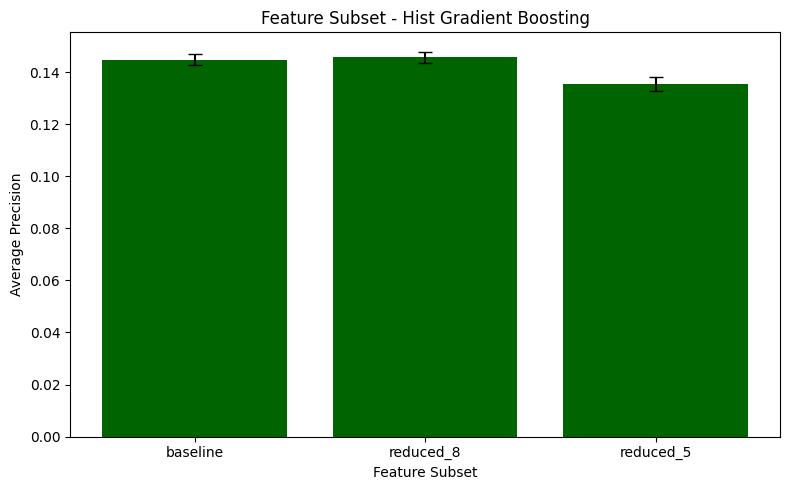

In [86]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    results_df["experiment"],
    results_df["ap_mean"],
    yerr=results_df["ap_std"],
    capsize=5,
    color="darkgreen"
)

ax.set_title("Feature Subset - Hist Gradient Boosting")
ax.set_xlabel("Feature Subset")
ax.set_ylabel("Average Precision")

plt.tight_layout()
plt.show()

### Feature Subset Evaluation: HistGradientBoosting 

The eight-feature HistGradientBoosting configuration achieved a slightly higher mean Average Precision than the ten-feature baseline (0.1457 vs. 0.1447), corresponding to an absolute improvement of approximately 0.0009.

The improvement was observed across all five cross-validation folds, suggesting a consistent, although small, benefit from removing the two lowest-ranked features identified by Permutation Feature Importance.

The reduced model also maintained comparable ROC-AUC performance, indicating that feature reduction did not materially affect overall discrimination under the evaluated configuration.

These results support retaining the eight-feature subset as a candidate for subsequent modeling experiments, while preserving the complete feature set as a benchmark.

In [88]:
with mlflow.start_run(
    run_name="hist-gradient-boosting-feature-subset-evaluation"
):

    # Experiment configuration
    mlflow.log_params({
        "analysis": "feature_subset_evaluation",
        "model": "HistGradientBoostingClassifier",
        "selection_method": "permutation_importance",
        "cv_strategy": "StratifiedKFold",
        "n_splits": 5,
        "random_state": 42,
        "primary_metric": "average_precision",
        "imputer": "median",
    })

    # Evaluation metrics
    for _, row in results_df.iterrows():

        name = row["experiment"]

        for metric in [
            "ap_mean",
            "ap_std",
            "roc_auc_mean",
            "roc_auc_std",
            "delta_ap",
        ]:
            mlflow.log_metric(
                f"{name}_{metric}",
                float(row[metric]),
            )

    # Feature subsets
    mlflow.log_dict(
        feature_sets,
        "feature_selection/feature_subsets.json",
    )

    # Results table
    mlflow.log_table(
        results_df,
        "feature_selection/subset_comparison.json",
    )

    # Comparison plot
    mlflow.log_figure(
        fig,
        "feature_selection/subset_comparison.png",
    )

    # Results per fold
    mlflow.log_table(
    fold_df,
    "feature_selection/fold_results.json",
    )

    mlflow.log_text(
    """
    # Feature Subset Evaluation: HistGradientBoosting Conclusions

    The evaluation compared HistGradientBoosting models with
    10, 8, and 5 features using five-fold stratified cross-validation.

    The eight-feature configuration achieved the highest Average
    Precision (0.1457 vs. 0.1447 for the baseline), with consistent
    improvements across all five folds and comparable ROC-AUC.

    Reducing the feature set to five predictors resulted in a
    more substantial performance decline (AP = 0.1354).

    These findings support retaining the eight-feature subset
    as the primary candidate for subsequent experiments, while
    preserving the complete feature set as a benchmark.
    """,
        "feature_selection/hgb_conclusions.md",
    )

### 4. Conclusions

This notebook evaluated feature relevance and selection through **Correlation Analysis, Permutation Feature Importance, and Feature Subset Evaluation**, comparing Logistic Regression and HistGradientBoosting.

The main findings were:

- **Correlation Analysis:** Most features exhibited weak linear correlations with the target and limited multicollinearity.
- **Permutation Feature Importance:** `CC_UTIL_MEAN` emerged as the most influential predictor in both models, while HistGradientBoosting demonstrated greater dependence on additional features.
- **Logistic Regression:** Reducing the feature set from 10 to 5 predictors resulted in a marginal AP decrease (0.1349 to 0.1338), suggesting limited incremental contribution from the excluded features.
- **HistGradientBoosting:** The eight-feature configuration slightly improved AP (0.1447 to 0.1457), with consistent gains across all five validation folds. Further reduction to five features decreased AP to 0.1354.

Overall, **HistGradientBoosting achieved higher predictive performance**, while Logistic Regression proved less sensitive to feature reduction. The eight-feature HistGradientBoosting configuration will be retained as the primary candidate, alongside the complete feature set for benchmarking.

These findings provide a foundation for subsequent class imbalance experiments and hyperparameter optimization.